In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 52.6 MB/s eta 0:00:00


In [ ]:
!wget https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/abc.zip

--2026-09-22 07:54:27--  https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/abc.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1487851 (1.4M) [application/zip]
Saving to: ‘abc.zip’

abc.zip             100%[===================>]   1.42M  --.-KB/s    in 0.03s   

2026-09-22 07:54:27 (40.5 MB/s) - ‘abc.zip’ saved [1487851/1487851]



In [ ]:
!unzip abc.zip

Archive:  abc.zip
   creating: abc/
  inflating: abc/README              
  inflating: abc/rural.txt           
  inflating: abc/science.txt         


# Task 1

In [ ]:
data_path = [ "/content/abc/rural.txt"]

In [ ]:
import string
string.punctuation
import re

In [ ]:
data = []
for path in data_path:
  with open(path, "r", encoding="utf-8") as f:
    temp = f.read().lower()
    # for i in string.punctuation:
    temp = re.sub(rf"[{string.punctuation}]", "", temp)
    data += temp.split("\n")
data.remove("")
data[:10]

['pm denies knowledge of awb kickbacks',
 'the prime minister has denied he knew awb was paying kickbacks to iraq despite writing to the wheat exporter asking to be kept fully informed on iraq wheat sales',
 'letters from john howard and deputy prime minister mark vaile to awb have been released by the cole inquiry into the oil for food program',
 'in one of the letters mr howard asks awb managing director andrew lindberg to remain in close contact with the government on iraq wheat sales',
 'the oppositions gavan oconnor says the letter was sent in 2002 the same time awb was paying kickbacks to iraq though a jordanian trucking company',
 'he says the government can longer wipe its hands of the illicit payments which totalled 290 million',
 'the responsibility for this must lay may squarely at the feet of coalition ministers in trade agriculture and the prime minister he said',
 'but the prime minister says letters show he was inquiring about the future of wheat sales in iraq and do not

In [ ]:
sentences = [i.split(" ") for i in data]
sentences[:3]

[['pm', 'denies', 'knowledge', 'of', 'awb', 'kickbacks'],
 ['the',
  'prime',
  'minister',
  'has',
  'denied',
  'he',
  'knew',
  'awb',
  'was',
  'paying',
  'kickbacks',
  'to',
  'iraq',
  'despite',
  'writing',
  'to',
  'the',
  'wheat',
  'exporter',
  'asking',
  'to',
  'be',
  'kept',
  'fully',
  'informed',
  'on',
  'iraq',
  'wheat',
  'sales'],
 ['letters',
  'from',
  'john',
  'howard',
  'and',
  'deputy',
  'prime',
  'minister',
  'mark',
  'vaile',
  'to',
  'awb',
  'have',
  'been',
  'released',
  'by',
  'the',
  'cole',
  'inquiry',
  'into',
  'the',
  'oil',
  'for',
  'food',
  'program']]

In [ ]:
import gensim

In [ ]:
model = gensim.models.Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    sg = 0, # CBOW
    epochs = 5
)

In [ ]:
vocab = model.wv.key_to_index
vocab = list(vocab.keys())
vocab

['the',
 'to',
 'of',
 'and',
 'a',
 'in',
 'is',
 'for',
 'says',
 '',
 'that',
 'are',
 'has',
 'he',
 'have',
 'it',
 'said',
 'from',
 'on',
 'be',
 'will',
 'with',
 'at',
 'we',
 'but',
 'been',
 'not',
 'its',
 'new',
 'australia',
 'farmers',
 'they',
 'this',
 'by',
 'as',
 'there',
 'australian',
 'water',
 'more',
 'an',
 'up',
 'growers',
 'their',
 'industry',
 'south',
 'was',
 'about',
 'government',
 'i',
 'year',
 'which',
 'per',
 'were',
 'wheat',
 'out',
 'prices',
 'some',
 'us',
 'cent',
 'years',
 'federal',
 'over',
 'one',
 'million',
 'than',
 'can',
 'now',
 'market',
 'so',
 'being',
 'if',
 'into',
 'people',
 'or',
 'would',
 'could',
 'last',
 'awb',
 'because',
 'australias',
 'national',
 'drought',
 'all',
 'had',
 'after',
 'just',
 'queensland',
 'what',
 'grain',
 'mr',
 'wool',
 'think',
 'get',
 'also',
 'cattle',
 'very',
 'company',
 'going',
 'time',
 'rural',
 'wales',
 'you',
 'western',
 'our',
 'price',
 'farm',
 'other',
 'say',
 'states',

# Task 2

In [ ]:
model.wv["australian"]

array([-0.2950236 ,  0.9840138 ,  0.21373987,  0.44262645,  0.23679827,
       -0.64915717,  1.4981732 ,  1.3862542 , -0.2559936 , -0.13526753,
       -0.550209  , -1.002761  ,  0.9970074 ,  0.5731918 , -0.14179942,
       -0.48893827,  0.811906  ,  0.0944141 ,  0.13366756, -1.8893982 ,
       -0.32311943, -0.45833737, -1.1224903 , -0.31548363, -0.8604817 ,
        0.21575283, -0.17999192,  0.42836392, -0.7976065 , -0.40419134,
        1.1013318 ,  1.2226465 ,  0.39759597, -0.66102946, -0.96091634,
        1.5807273 ,  0.43522125, -0.0936589 ,  0.13876721, -0.92902356,
       -0.9383102 , -0.28851986, -0.18948838, -0.33478755, -0.5451792 ,
        0.43516833, -0.12154064,  0.8559365 , -0.30612546,  0.33014676,
       -0.15177155, -0.0576662 , -0.43724632, -1.2256551 ,  0.3107045 ,
       -0.6764207 ,  1.1244925 , -0.6742502 , -0.14896204,  0.0237131 ,
        0.0867608 , -0.7412998 , -0.01435597, -0.5451172 , -0.51316535,
        0.24355339, -0.29771844,  0.85825545, -1.9496659 ,  1.01

In [ ]:
import numpy as np


In [ ]:
def similarity(w1, w2):
  v1 = model.wv[w1]
  v2 = model.wv[w2]
  cos_sim = (v1@v2) / np.linalg.norm(v1) / np.linalg.norm(v2)
  return cos_sim



In [ ]:
similarity("incomes", "prices")

np.float32(0.90478796)

In [ ]:
model.wv.most_similar(positive = "prices", topn = 10)

[('their', 0.9170289039611816),
 ('sheep', 0.9126273393630981),
 ('incomes', 0.9047878384590149),
 ('soaring', 0.9034771919250488),
 ('production', 0.9025768637657166),
 ('feed', 0.9013583064079285),
 ('higher', 0.9006447792053223),
 ('manufacturers', 0.8978990316390991),
 ('costs', 0.8973424434661865),
 ('lower', 0.8963146209716797)]

# Task 3

In [ ]:
import random
random.shuffle

<bound method Random.shuffle of <random.Random object at 0x2c6882e0>>

In [ ]:
N = 1000
new_covab = vocab.copy()
random.shuffle(new_covab)
new_covab = new_covab[:N]
new_covab[:3]

['rejecting', 'innal', 'ginger']

In [ ]:
vecs = np.array([model.wv[i] for i in new_covab])
vecs.shape, vecs

((1000, 100),
 array([[-0.00748116,  0.03158153,  0.01001963, ..., -0.01649793,
         -0.00363913,  0.00263756],
        [ 0.00220706,  0.00803408, -0.0015531 , ..., -0.0112298 ,
          0.00209104,  0.00173147],
        [-0.00485464,  0.02422361,  0.00934444, ..., -0.00789151,
          0.00436427,  0.00993326],
        ...,
        [-0.00726582,  0.00587067,  0.01072671, ..., -0.00746866,
          0.01238199,  0.00211975],
        [-0.00107456,  0.01475015,  0.00292696, ..., -0.01759899,
         -0.00534733,  0.0007353 ],
        [ 0.00219668,  0.02150699,  0.00777491, ..., -0.03400498,
         -0.0047179 ,  0.00607933]], dtype=float32))

In [ ]:
import sklearn

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit(vecs)

PCA(n_components=2)

In [ ]:
pca.transform(vecs).shape

(1000, 2)

In [ ]:
import pandas as pd
import seaborn as sns

In [ ]:
df = pd.DataFrame(np.concat([pca.transform(vecs)*10, np.array(new_covab).reshape(-1,1)], axis = 1), columns=["X", "Y", "word"])
# df = pd.DataFrame(np.concat([vecs[:,:2], np.array(new_covab).reshape(-1,1)], axis = 1), columns=["X", "Y", "word"])
df.head()

,X,Y,word
0,2.9046795,0.16689768,rejecting
1,4.3316708,-0.1027827,innal
2,3.7221856,-0.17823797,ginger
3,-8.1056385,-1.5676382,researchers
4,3.9537776,0.17598635,butchered


<Axes: xlabel='X', ylabel='Y'>

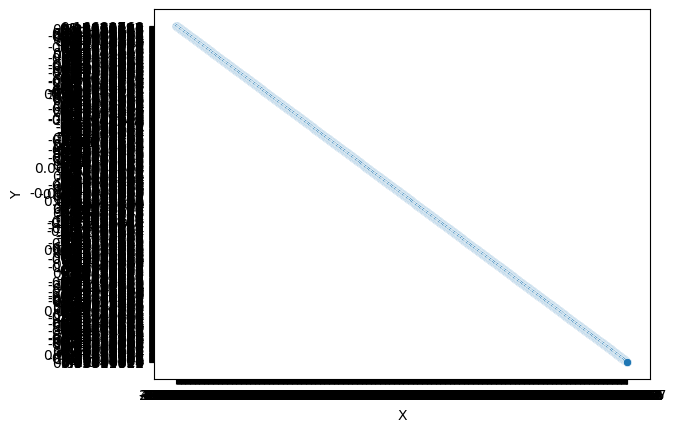

In [ ]:
sns.scatterplot(data=df, x="X", y="Y")

TASK 3 BTVN

In [ ]:
model_sg = gensim.models.Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,  # sg=1 đại diện cho Skip-gram
    epochs=5,
)

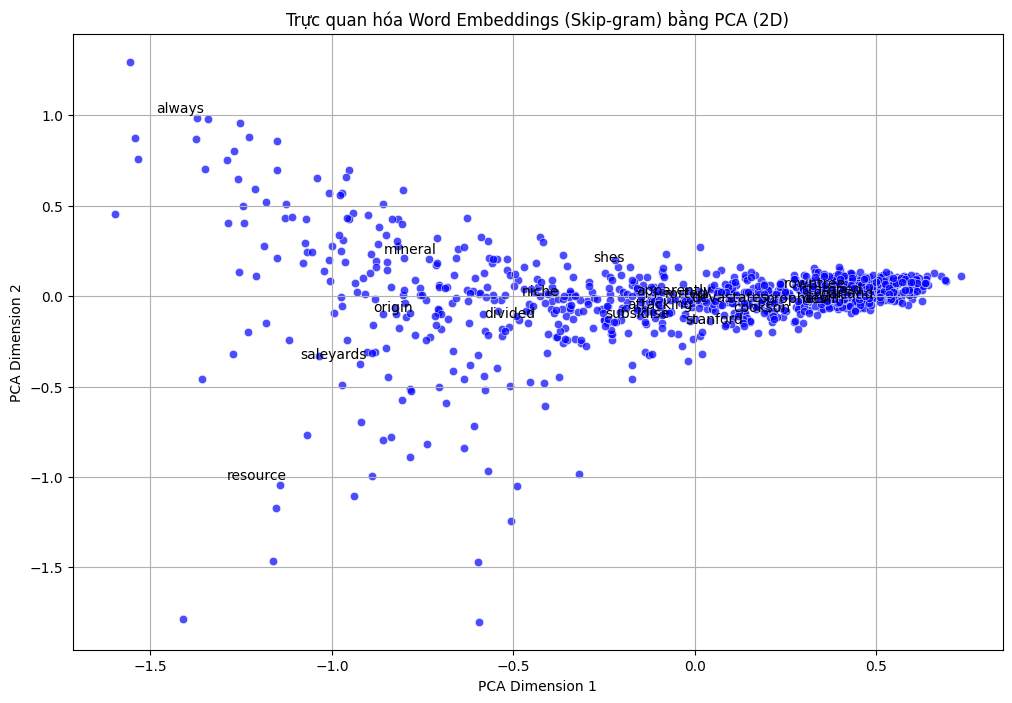

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Lấy danh sách từ vựng từ mô hình Skip-gram
vocab_sg = list(model_sg.wv.key_to_index.keys())
N = 1000
new_vocab_sg = vocab_sg.copy()
random.shuffle(new_vocab_sg)
new_vocab_sg = new_vocab_sg[:N]

# vector tương ứng với các từ đã chọn
vecs_sg = np.array([model_sg.wv[word] for word in new_vocab_sg])

# pca để giảm chiều dữ liệu về 2D
pca_sg = PCA(n_components=2)
vecs_2d_sg = pca_sg.fit_transform(vecs_sg)

df_sg = pd.DataFrame(
    {"X": vecs_2d_sg[:, 0], "Y": vecs_2d_sg[:, 1], "word": new_vocab_sg}
)

# Seaborn/Matplotlib
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_sg, x="X", y="Y", alpha=0.7, color="blue")

# Thêm nhãn một số từ ngẫu nhiên để quan sát rõ hơn
for i in range(20):
    plt.annotate(
        df_sg["word"][i],
        xy=(df_sg["X"][i], df_sg["Y"][i]),
        xytext=(5, 2),
        textcoords="offset points",
        ha="right",
        va="bottom",
    )

plt.title("Trực quan hóa Word Embeddings (Skip-gram) bằng PCA (2D)")
plt.xlabel("PCA Dimension 1")
plt.ylabel("PCA Dimension 2")
plt.grid(True)
plt.show()